## model

In [1]:
import numpy as np
import pickle
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import copy

class ReLU:
    def forward(self, x):
        return np.maximum(0, x)
    
    def backward(self, x):
        return np.where(x > 0, 1, 0)

class Sigmoid:
    def forward(self, x):
        return 1 / (1 + np.exp(-x))
    
    def backward(self, x):
        s = self.forward(x)
        return s * (1 - s)

class Linear:
    def forward(self, x):
        return x
    
    def backward(self, x):
        return 1
    
class Tanh():
    def forward(self, x):
        return np.tanh(x)

    def backward(self, x):
        return 1 - np.tanh(x) ** 2

class DenseLayer:
    def __init__(self, num_inputs, num_neurons, activation_func=Linear()):
        self.num_inputs = num_inputs
        self.num_neurons = num_neurons
        self.activation_func = activation_func
        self.weights = np.random.uniform(-1, 1, (num_neurons, num_inputs))
        self.biases = np.random.uniform(-1, 1, num_neurons)
        
        # Storage for forward pass
        self.inputs = None
        self.z = None  # Pre-activation
        self.output = None  # Post-activation
        
        # Storage for gradients
        self.dweights = None
        self.dbiases = None
        
    def forward(self, inputs):
        self.inputs = inputs
        if inputs.ndim == 1:
            self.inputs = inputs.reshape(1, -1)
            
        self.z = np.dot(self.inputs, self.weights.T) + self.biases
        self.output = self.activation_func.forward(self.z)
        return self.output
    
    def backward(self, gradient):
        # Calculate gradients through activation function
        d_activation = self.activation_func.backward(self.z) * gradient
        
        # Calculate gradients w.r.t weights and biases
        self.dweights = np.dot(d_activation.T, self.inputs)
        self.dbiases = np.sum(d_activation, axis=0)
        
        # Calculate gradient for next layer
        return np.dot(d_activation, self.weights)

class GradientDescentOptimizer:
    def __init__(self, learning_rate=0.01):
        self.learning_rate = learning_rate
        self.epsilon = 1e-8  # Для числової стабільності
        
    def normalize_gradients(self, gradients):
        # Нормалізація градієнтів за допомогою L2 норми
        grad_norm = np.sqrt(np.sum(gradients * gradients) + self.epsilon)
        return gradients / grad_norm if grad_norm > self.epsilon else gradients
        
    def update_params(self, layer):
        # Нормалізуємо градієнти
        normalized_dweights = self.normalize_gradients(layer.dweights)
        normalized_dbiases = self.normalize_gradients(layer.dbiases)
        
        # Застосовуємо градієнтний спуск з нормалізованими градієнтами
        layer.weights -= self.learning_rate * normalized_dweights
        layer.biases -= self.learning_rate * normalized_dbiases


class NeuralNetwork:
    def __init__(self, input_size):
        self.input_size = input_size
        self.layers = []
        
    def add_layer(self, layer):
        if not self.layers:
            if layer.num_inputs != self.input_size:
                raise ValueError("First layer must match input size")
        else:
            if layer.num_inputs != self.layers[-1].num_neurons:
                raise ValueError("Layer input size must match previous layer output size")
        self.layers.append(layer)
        
    def forward(self, X):
        output = X
        for layer in self.layers:
            output = layer.forward(output)
        return output
    
    def backward(self, y_true, y_pred):
        batch_size = y_true.shape[0]
        # MSE derivative
        gradient = 2 * (y_pred - y_true) / batch_size
        
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)
    
    def train_step(self, X, y, optimizer):
        # Forward pass
        predictions = self.forward(X)
        
        # Backward pass
        self.backward(y, predictions)
        
        # Update weights
        for layer in self.layers:
            optimizer.update_params(layer)
        
        # Calculate loss
        loss = np.mean((predictions - y) ** 2)
        return loss
    
    def fit(self, X, y, epochs=1000, verbose=True, optimizer=GradientDescentOptimizer(learning_rate=0.01)):
        optimizer = optimizer
        history = []
        
        for epoch in range(epochs):
            loss = self.train_step(X, y, optimizer)
            history.append(loss)
            
            if verbose and epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.6f}")
                
        return history

    def save_weights(self, filepath):
        with open(filepath, 'wb') as f:
            layer_params = [(layer.weights, layer.biases) for layer in self.layers]
            pickle.dump(layer_params, f)

    def load_weights(self, filepath):
        with open(filepath, 'rb') as f:
            layer_params = pickle.load(f)
            for layer, (weights, biases) in zip(self.layers, layer_params):
                layer.weights = weights
                layer.biases = biases

## training

In [2]:
df = sm.datasets.macrodata.load_pandas().data

def create_date(row):
    return pd.Timestamp(year=int(row['year']), month=int(row['quarter'] * 3 - 2), day=1)

df['date'] = df.apply(create_date, axis=1)


X = df[['realgdp', 'realcons', 'realinv', 'realgovt',
        'realdpi', 'm1', 'tbilrate', 'unemp', 'pop', 'infl', 'realint']].values
y = df['cpi'].values 

y = y.reshape(-1, 1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = NeuralNetwork(X.shape[1])
model.add_layer(DenseLayer(num_inputs=X.shape[1], num_neurons=8, activation_func=ReLU()))
model.add_layer(DenseLayer(num_inputs=8, num_neurons=1, activation_func=Linear()))

optimizer = GradientDescentOptimizer(learning_rate=0.01)

model.load_weights('full_model_weights.pkl')

Training on window 1 (0-50)
Epoch 0, Loss: 0.192063
Epoch 100, Loss: 0.151213
Epoch 200, Loss: 0.137598
Epoch 300, Loss: 0.128031
Epoch 400, Loss: 0.120683
Epoch 500, Loss: 0.114684
Epoch 600, Loss: 0.109567
Epoch 700, Loss: 0.105015
Epoch 800, Loss: 0.101311
Epoch 900, Loss: 0.098180


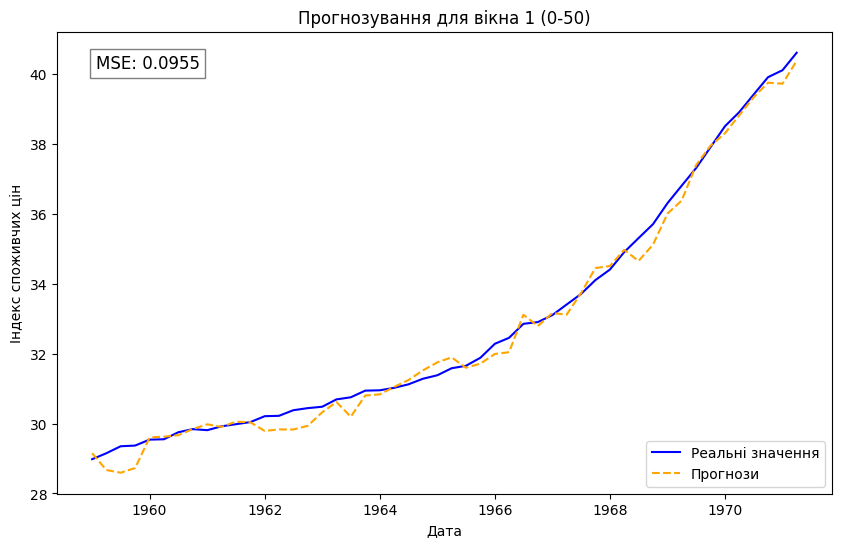

Training on window 2 (1-51)
Epoch 0, Loss: 0.094990
Epoch 100, Loss: 0.091390
Epoch 200, Loss: 0.087481
Epoch 300, Loss: 0.085322
Epoch 400, Loss: 0.083981
Epoch 500, Loss: 0.082756
Epoch 600, Loss: 0.081578
Epoch 700, Loss: 0.080459
Epoch 800, Loss: 0.079389
Epoch 900, Loss: 0.078363


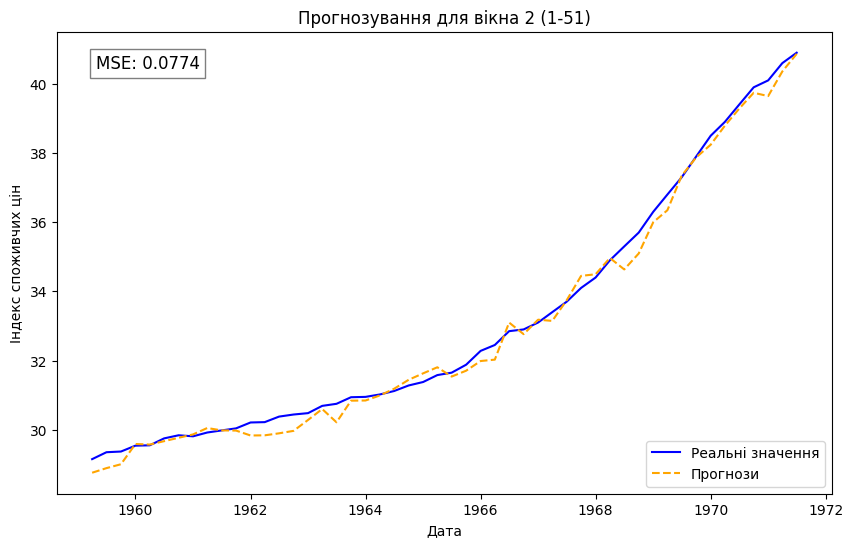

Training on window 3 (2-52)
Epoch 0, Loss: 0.081509
Epoch 100, Loss: 0.078670
Epoch 200, Loss: 0.077363
Epoch 300, Loss: 0.076029
Epoch 400, Loss: 0.074704
Epoch 500, Loss: 0.073414
Epoch 600, Loss: 0.071982
Epoch 700, Loss: 0.070778
Epoch 800, Loss: 0.069569
Epoch 900, Loss: 0.068807


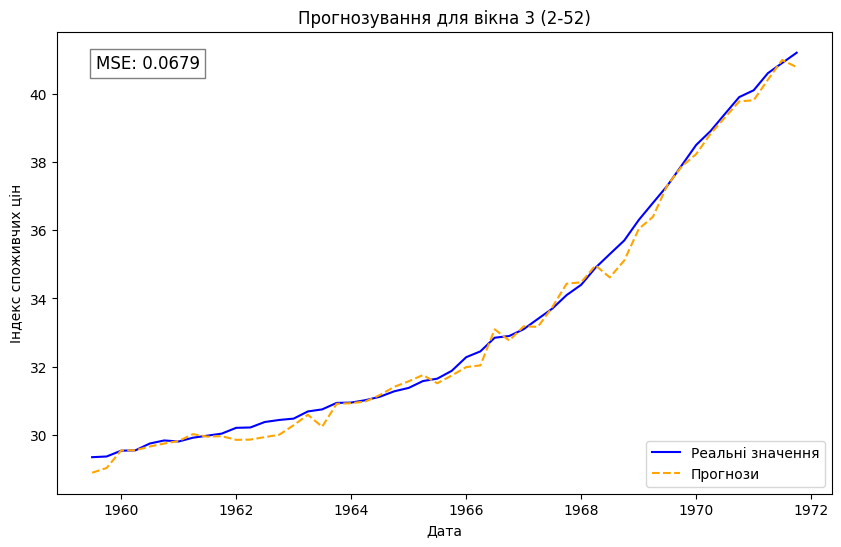

Training on window 4 (3-53)
Epoch 0, Loss: 0.090707
Epoch 100, Loss: 0.083712
Epoch 200, Loss: 0.081210
Epoch 300, Loss: 0.079142
Epoch 400, Loss: 0.076827
Epoch 500, Loss: 0.074328
Epoch 600, Loss: 0.072158
Epoch 700, Loss: 0.070313
Epoch 800, Loss: 0.068722
Epoch 900, Loss: 0.067406


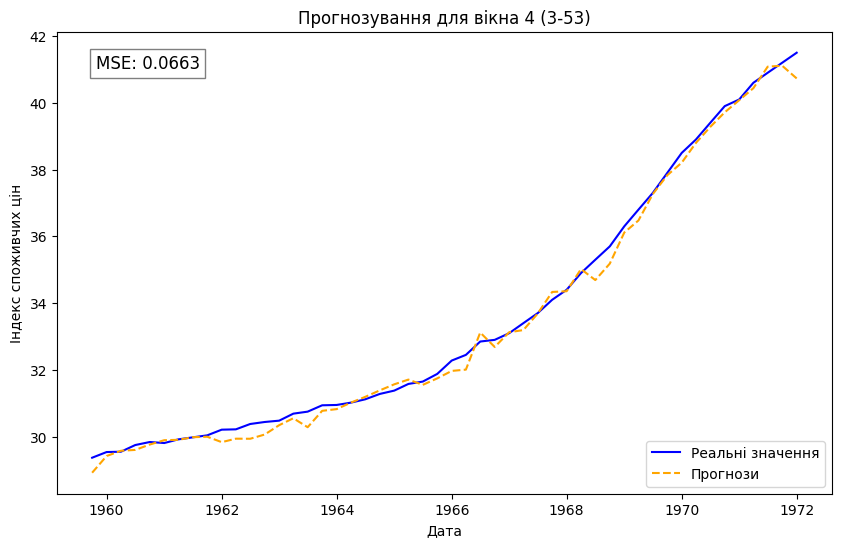

Training on window 5 (4-54)
Epoch 0, Loss: 0.075150
Epoch 100, Loss: 0.070556
Epoch 200, Loss: 0.068247
Epoch 300, Loss: 0.066458
Epoch 400, Loss: 0.065067
Epoch 500, Loss: 0.063930
Epoch 600, Loss: 0.062930
Epoch 700, Loss: 0.061680
Epoch 800, Loss: 0.059602
Epoch 900, Loss: 0.058695


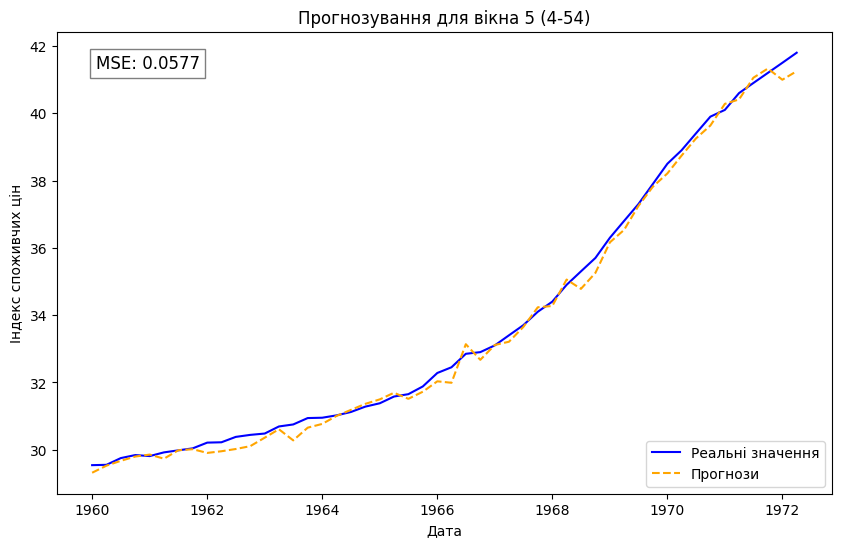

Training on window 6 (5-55)
Epoch 0, Loss: 0.066468
Epoch 100, Loss: 0.064168
Epoch 200, Loss: 0.062483
Epoch 300, Loss: 0.060886
Epoch 400, Loss: 0.059616
Epoch 500, Loss: 0.058428
Epoch 600, Loss: 0.057277
Epoch 700, Loss: 0.056185
Epoch 800, Loss: 0.055103
Epoch 900, Loss: 0.054075


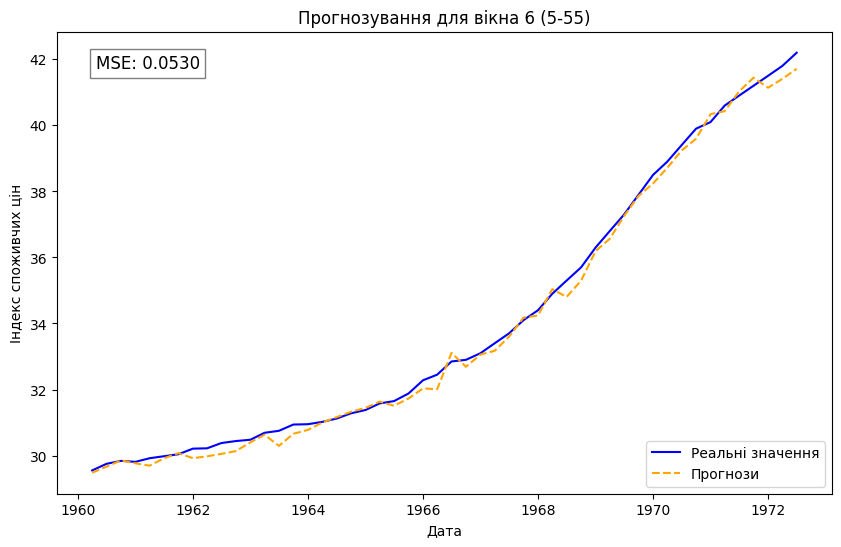

Training on window 7 (6-56)
Epoch 0, Loss: 0.058270
Epoch 100, Loss: 0.056325
Epoch 200, Loss: 0.054768
Epoch 300, Loss: 0.053476
Epoch 400, Loss: 0.052408
Epoch 500, Loss: 0.051565
Epoch 600, Loss: 0.050859
Epoch 700, Loss: 0.050198
Epoch 800, Loss: 0.049577
Epoch 900, Loss: 0.048990


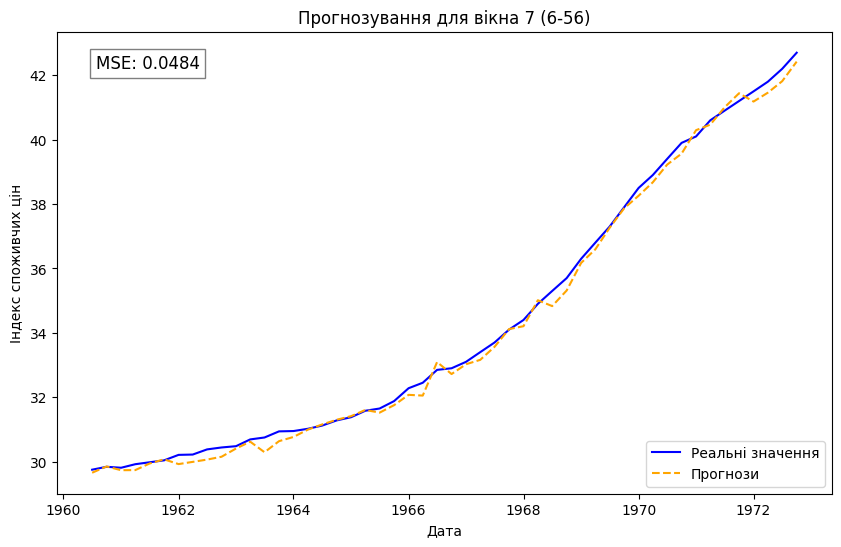

Training on window 8 (7-57)
Epoch 0, Loss: 0.049127
Epoch 100, Loss: 0.048497
Epoch 200, Loss: 0.047966
Epoch 300, Loss: 0.047474
Epoch 400, Loss: 0.047014
Epoch 500, Loss: 0.046582
Epoch 600, Loss: 0.046173
Epoch 700, Loss: 0.045809
Epoch 800, Loss: 0.045461
Epoch 900, Loss: 0.045126


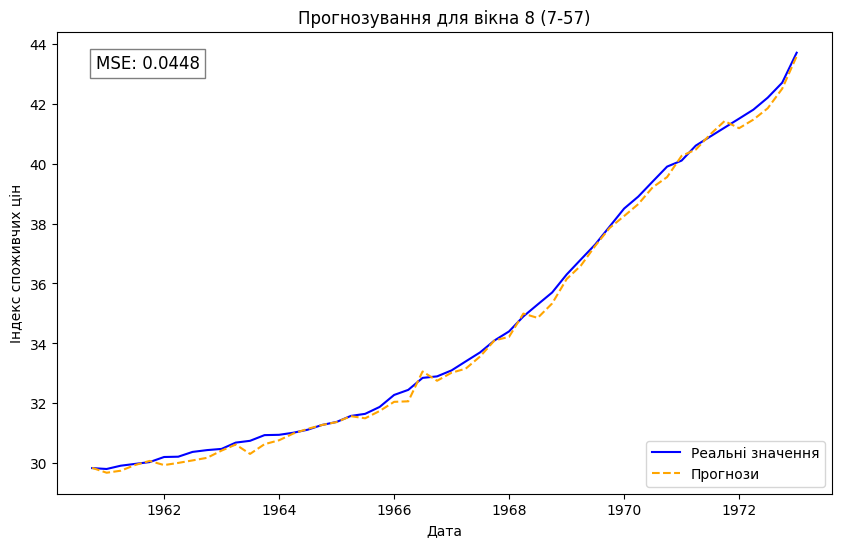

Training on window 9 (8-58)
Epoch 0, Loss: 0.062637
Epoch 100, Loss: 0.057269
Epoch 200, Loss: 0.055987
Epoch 300, Loss: 0.055039
Epoch 400, Loss: 0.054252
Epoch 500, Loss: 0.053561
Epoch 600, Loss: 0.052930
Epoch 700, Loss: 0.052345
Epoch 800, Loss: 0.051801
Epoch 900, Loss: 0.051291


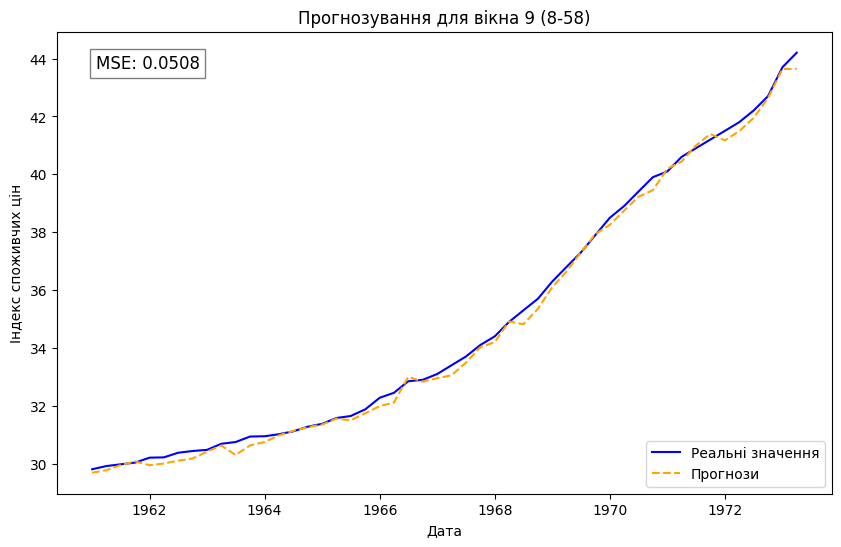

Training on window 10 (9-59)
Epoch 0, Loss: 0.054243
Epoch 100, Loss: 0.052898
Epoch 200, Loss: 0.052321
Epoch 300, Loss: 0.051823
Epoch 400, Loss: 0.051376
Epoch 500, Loss: 0.050967
Epoch 600, Loss: 0.050588
Epoch 700, Loss: 0.050236
Epoch 800, Loss: 0.049904
Epoch 900, Loss: 0.049591


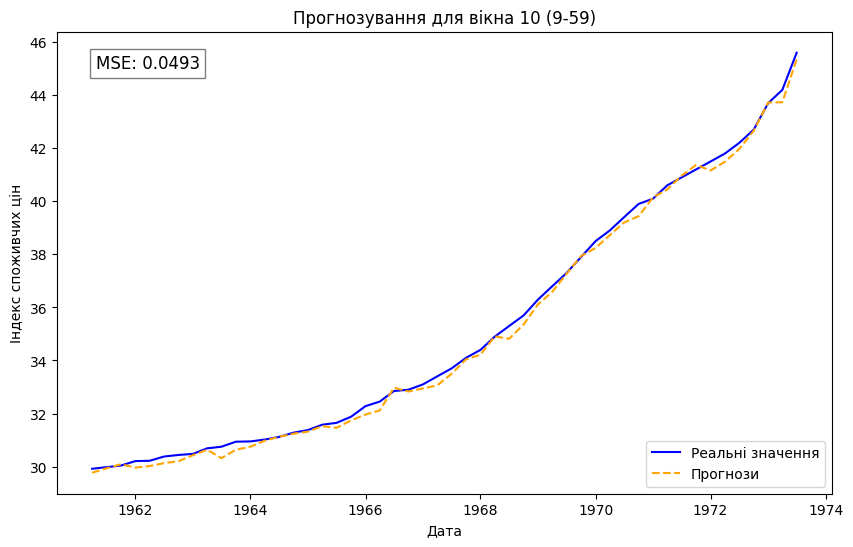

In [3]:
def sliding_window_training(X, y, folder, window_size=12, num_windows=10): 
    for window in range(num_windows):  # Цикл для всіх вікон
        start_index = window
        end_index = start_index + window_size
        
        if end_index > len(X):
            print("End of data reached.")
            break
        
        print(f"Training on window {window + 1} ({start_index}-{end_index})")
        
        X_window = X[start_index:end_index] 
        y_window = y[start_index:end_index]

        # Навчання мережі на поточному вікні
        model.fit(X_window, y_window, epochs=1000, optimizer=optimizer)
        # Прогнозування 
        predictions = model.forward(X_window)

        # Розрахунок DELTA та DELTA^2
        delta = predictions.flatten() - y_window.flatten()
        delta_squared = delta ** 2
        
        # Підготовка даних для таблиці
        results_df = pd.DataFrame({
            'Point': np.arange(window_size)[::-1],
            'IPC RO': y_window.flatten(),
            'IPC PO': predictions.flatten(),
            'DELTA': delta,
            'DELTA^2': delta_squared
        })
        
        # Обчислення TOTAL та MSE
        total_delta = delta.sum()
        total_delta_squared = delta_squared.sum()
        mse = np.mean(delta_squared)

        # Додавання підсумків до таблиці
        results_df.loc[len(results_df)] = ['TOTAL', '', total_delta, '', total_delta_squared]
        results_df.loc[len(results_df)] = ['MSE', '', '', '', mse]

        # Збереження результатів у Excel
        results_df.to_excel(f'{folder}/sliding_window_results_window_{window + 1}.xlsx', index=False)

        # Візуалізація
        plt.figure(figsize=(10, 6))
        plt.plot(df['date'][start_index:end_index], y_window, label='Реальні значення', color='blue')
        plt.plot(df['date'][start_index:end_index], predictions, label='Прогнози', linestyle='--', color='orange')
        plt.xlabel('Дата')
        plt.ylabel('Індекс споживчих цін')
        plt.title(f'Прогнозування для вікна {window + 1} ({start_index}-{end_index})')
        plt.legend()

        plt.text(0.05, 0.95, f'MSE: {mse:.4f}', transform=plt.gca().transAxes,
                 fontsize=12, verticalalignment='top', bbox=dict(facecolor='white', alpha=0.5))

        plt.savefig(f'{folder}/window_{window + 1}_forecast.png')  # Зберігаємо графік
        plt.show()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
sliding_window_training(X_scaled, y, "full", window_size=50, num_windows=10)


In [4]:
X_part = df[['realgdp', 'realcons', 'realinv', 'realgovt']].values 
y_part = df['cpi'].values 

y_part = y_part.reshape(-1, 1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_part)

Training on window 1 (0-50)
Epoch 0, Loss: 0.077368
Epoch 100, Loss: 0.070615
Epoch 200, Loss: 0.068813
Epoch 300, Loss: 0.067889
Epoch 400, Loss: 0.067216
Epoch 500, Loss: 0.066731
Epoch 600, Loss: 0.066323
Epoch 700, Loss: 0.066021
Epoch 800, Loss: 0.065839
Epoch 900, Loss: 0.065674


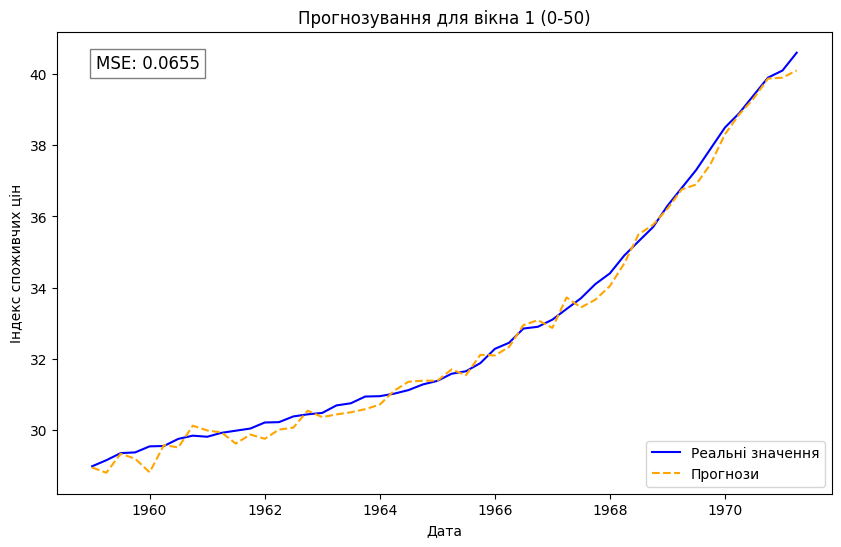

Training on window 2 (1-51)
Epoch 0, Loss: 0.070044
Epoch 100, Loss: 0.069224
Epoch 200, Loss: 0.068920
Epoch 300, Loss: 0.068694
Epoch 400, Loss: 0.068439
Epoch 500, Loss: 0.068230
Epoch 600, Loss: 0.068060
Epoch 700, Loss: 0.067933
Epoch 800, Loss: 0.067793
Epoch 900, Loss: 0.067672


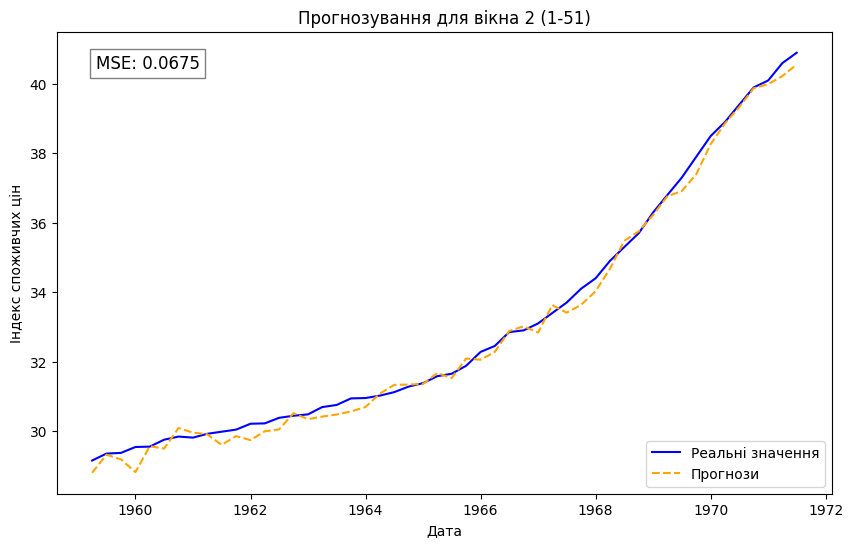

Training on window 3 (2-52)
Epoch 0, Loss: 0.083346
Epoch 100, Loss: 0.080393
Epoch 200, Loss: 0.079719
Epoch 300, Loss: 0.079174
Epoch 400, Loss: 0.078703
Epoch 500, Loss: 0.077966
Epoch 600, Loss: 0.076980
Epoch 700, Loss: 0.075914
Epoch 800, Loss: 0.075181
Epoch 900, Loss: 0.074230


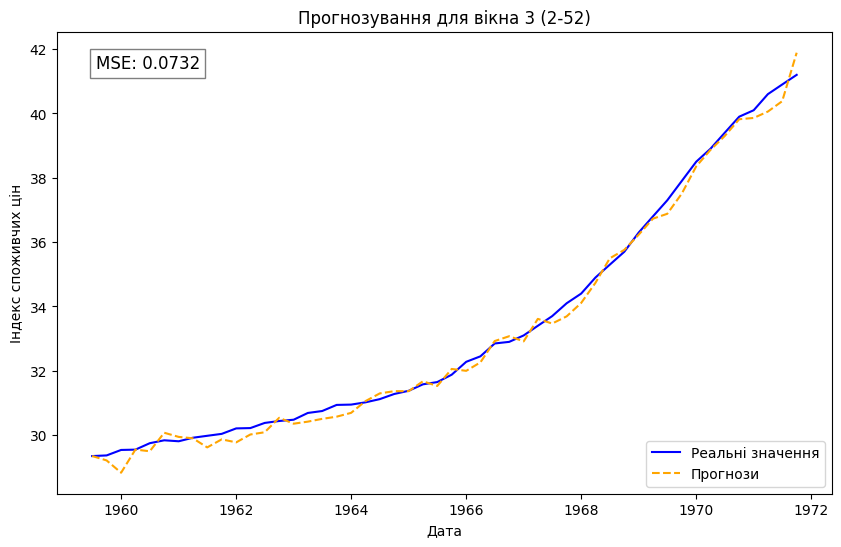

Training on window 4 (3-53)
Epoch 0, Loss: 0.074445
Epoch 100, Loss: 0.073462
Epoch 200, Loss: 0.072652
Epoch 300, Loss: 0.071666
Epoch 400, Loss: 0.070675
Epoch 500, Loss: 0.069941
Epoch 600, Loss: 0.069270
Epoch 700, Loss: 0.068611
Epoch 800, Loss: 0.067966
Epoch 900, Loss: 0.067339


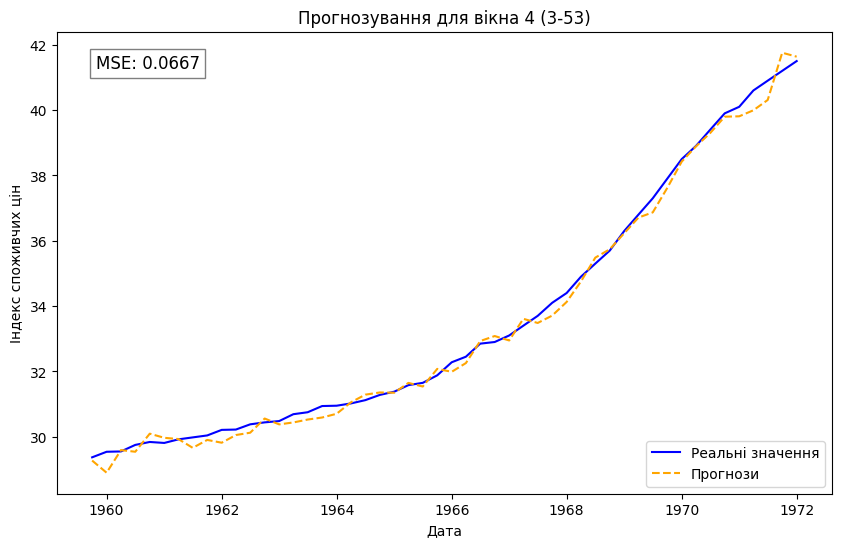

Training on window 5 (4-54)
Epoch 0, Loss: 0.066673
Epoch 100, Loss: 0.066212
Epoch 200, Loss: 0.065756
Epoch 300, Loss: 0.065278
Epoch 400, Loss: 0.064771
Epoch 500, Loss: 0.064189
Epoch 600, Loss: 0.063489
Epoch 700, Loss: 0.062922
Epoch 800, Loss: 0.062421
Epoch 900, Loss: 0.061965


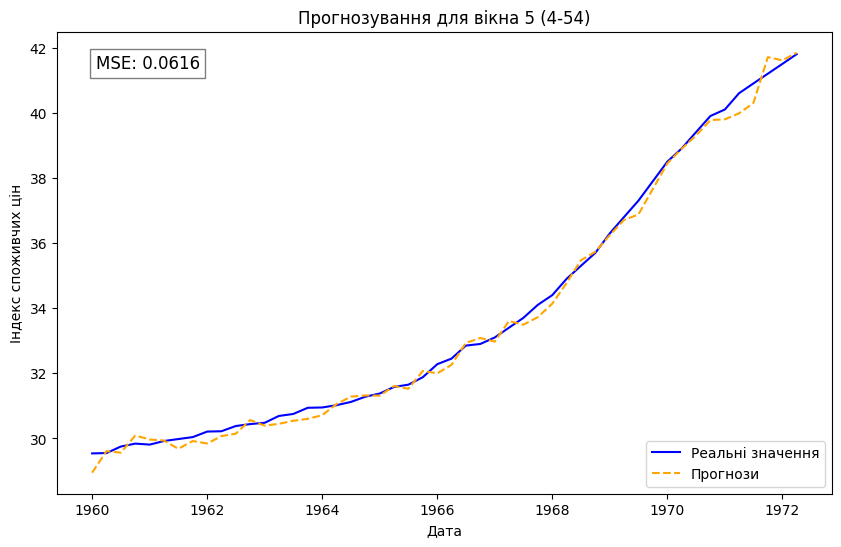

Training on window 6 (5-55)
Epoch 0, Loss: 0.063875
Epoch 100, Loss: 0.061380
Epoch 200, Loss: 0.060374
Epoch 300, Loss: 0.059775
Epoch 400, Loss: 0.059301
Epoch 500, Loss: 0.058810
Epoch 600, Loss: 0.058341
Epoch 700, Loss: 0.057958
Epoch 800, Loss: 0.057627
Epoch 900, Loss: 0.057319


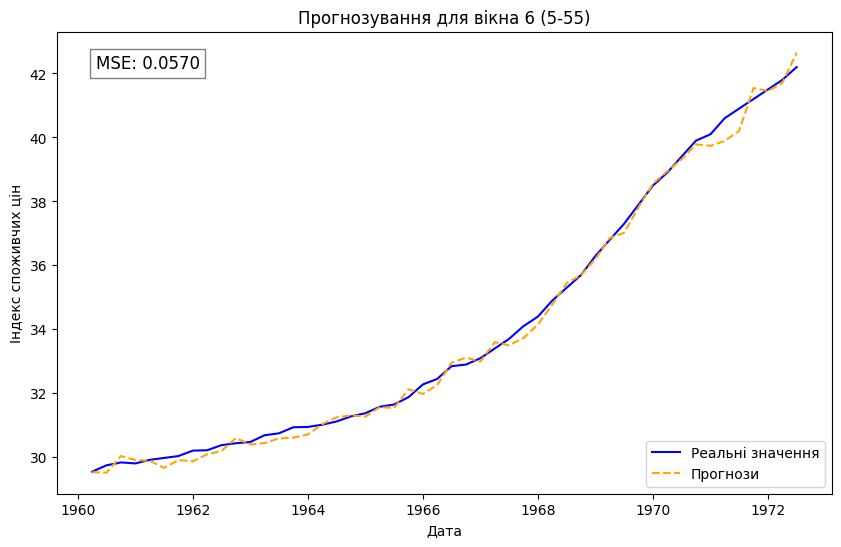

Training on window 7 (6-56)
Epoch 0, Loss: 0.086045
Epoch 100, Loss: 0.082248
Epoch 200, Loss: 0.081122
Epoch 300, Loss: 0.080723
Epoch 400, Loss: 0.080508
Epoch 500, Loss: 0.080349
Epoch 600, Loss: 0.080214
Epoch 700, Loss: 0.080093
Epoch 800, Loss: 0.079980
Epoch 900, Loss: 0.080090


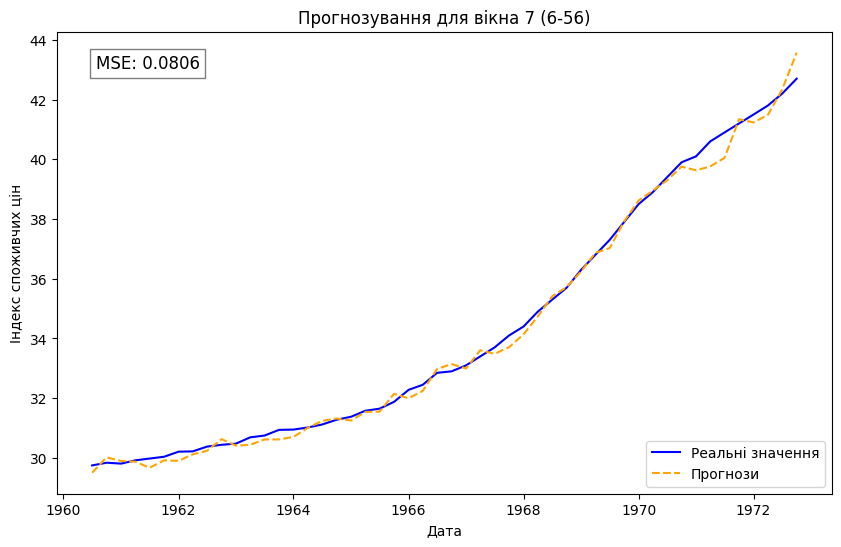

Training on window 8 (7-57)
Epoch 0, Loss: 0.079659
Epoch 100, Loss: 0.080200
Epoch 200, Loss: 0.080866
Epoch 300, Loss: 0.081156
Epoch 400, Loss: 0.081305
Epoch 500, Loss: 0.081408
Epoch 600, Loss: 0.081373
Epoch 700, Loss: 0.081510
Epoch 800, Loss: 0.081637
Epoch 900, Loss: 0.081710


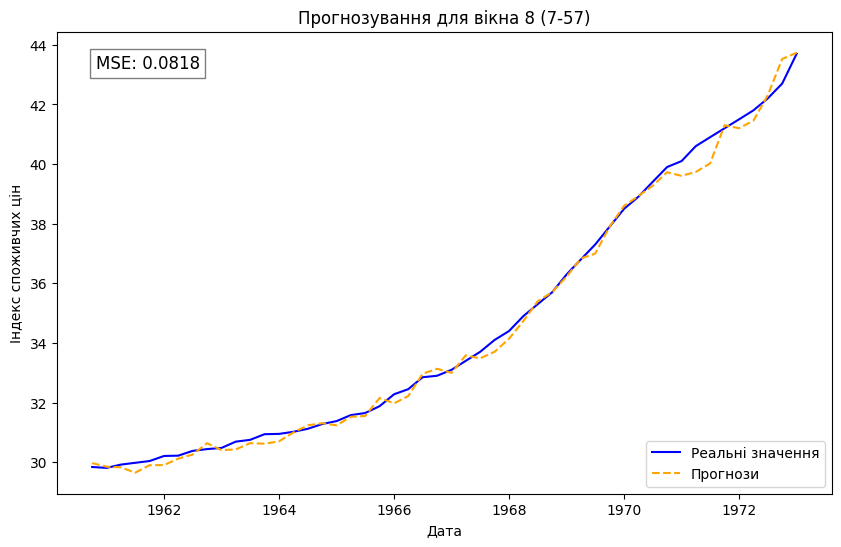

Training on window 9 (8-58)
Epoch 0, Loss: 0.091015
Epoch 100, Loss: 0.089620
Epoch 200, Loss: 0.089214
Epoch 300, Loss: 0.088989
Epoch 400, Loss: 0.088961
Epoch 500, Loss: 0.089052
Epoch 600, Loss: 0.089114
Epoch 700, Loss: 0.089256
Epoch 800, Loss: 0.089479
Epoch 900, Loss: 0.089759


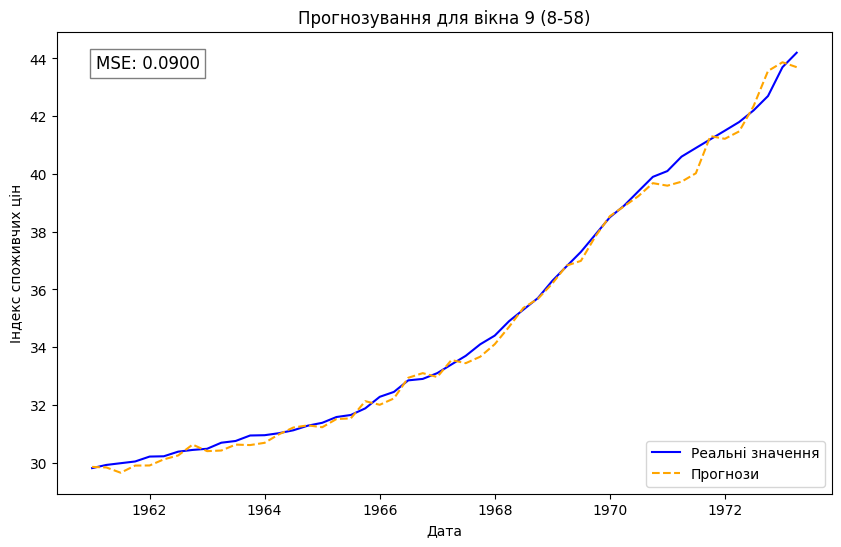

Training on window 10 (9-59)
Epoch 0, Loss: 0.129299
Epoch 100, Loss: 0.124299
Epoch 200, Loss: 0.123236
Epoch 300, Loss: 0.122812
Epoch 400, Loss: 0.122666
Epoch 500, Loss: 0.122392
Epoch 600, Loss: 0.121975
Epoch 700, Loss: 0.121238
Epoch 800, Loss: 0.120549
Epoch 900, Loss: 0.119863


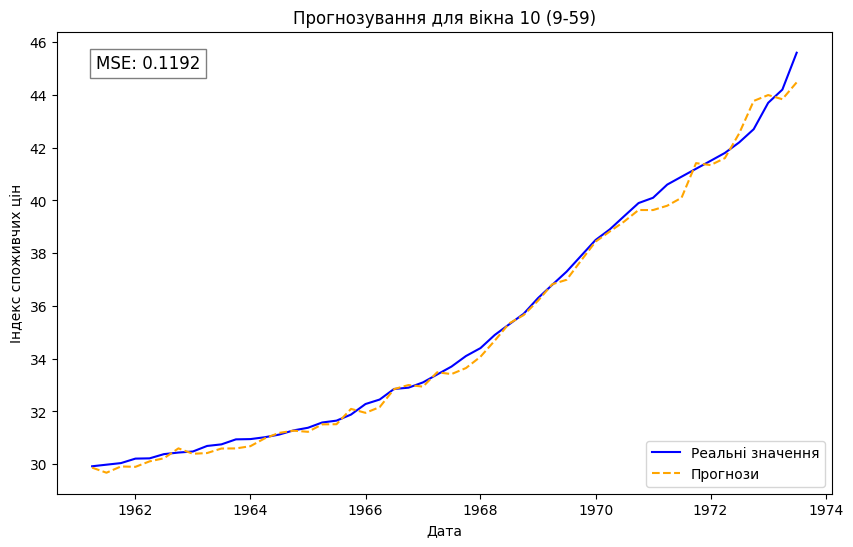

In [5]:
model = NeuralNetwork(X_part.shape[1])
model.add_layer(DenseLayer(num_inputs=X_part.shape[1], num_neurons=8, activation_func=ReLU()))
model.add_layer(DenseLayer(num_inputs=8, num_neurons=1, activation_func=Linear()))

model.load_weights('partial_model_weights.pkl')

optimizer = GradientDescentOptimizer(learning_rate=0.01)

sliding_window_training(X_scaled, y_part, "partial", window_size=50, num_windows=10)
